# Mol-1 Structure Prediction

[Mol-1](https://github.com/molence/Mol-1) predicts all-atom structures for protein, DNA, RNA, and ligand complexes. This notebook folds the 20-residue Trp-cage mini-protein, then demonstrates a two-chain insulin complex with token-level predicted aligned error (PAE).

See the [Mol-1 technical report](https://github.com/molence/Mol-1/blob/main/assets/report.pdf) for model details. This executed example uses your own Modal account. Set `device="cuda"` below to use a local NVIDIA GPU instead. The first call builds the managed environment and downloads the model assets.

In [1]:
from pathlib import Path

from IPython.display import display

from proto_tools import Chain, Complex
from proto_tools.tools.structure_prediction.mol1 import (
    Mol1Config,
    Mol1Input,
    run_mol1_prediction,
)
from proto_tools.utils.notebook_docs import display_api_reference

# Choose "cuda" to use a local NVIDIA GPU.
device = "modal"

## Input API

In [2]:
display_api_reference("mol1-prediction", "input", "run_mol1_prediction")

**Input** — `Mol1Input`

| Field | Type | Default | Description |
|-------|------|---------|-------------|
| <code>complexes</code> | <code>list[Complex]</code> | required | List of complexes to predict structure for containing chains and entity types. |
| <code>msas</code> | <code>list[ComplexMSAs] &#124; None</code> | <code>None</code> | Per-complex MSAs; a bare dict[int, MSA] is coerced to an unpaired ComplexMSAs. |

## Config API

In [3]:
display_api_reference("mol1-prediction", "config", "run_mol1_prediction")

**Config** — `Mol1Config`

| Field | Type | Default | Description |
|-------|------|---------|-------------|
| <code>device</code> | <code>str</code> | <code>'cuda'</code> | Device to run the model on (e.g., 'cuda', 'cpu') |
| <code>include_pae_matrix</code> | <code>bool</code> | <code>False</code> | Attach the full token-pair PAE matrix in angstroms. |
| <code>use_msa</code> | <code>bool</code> | <code>True</code> | Whether to auto-generate MSAs via MMseqs2 homology search; supplied MSAs are always used |
| <code>msa_search_config</code> | <code>Mmseqs2HomologySearchConfig &#124; None</code> | <code>None</code> | Nested MMseqs2 homology-search config for MSA generation; None uses default settings. |
| <code>pair_heterocomplex_msas</code> | <code>bool</code> | <code>True</code> | Whether heterocomplex protein chains should use taxonomy-paired MSA generation. |
| <code>model_checkpoint</code> | <code>str</code> | <code>'mol-1-base'</code> | Bundled 'mol-1-base' or a path to a custom Mol-1 .pt checkpoint. |
| <code>num_samples</code> | <code>int</code> | <code>5</code> | Diffusion samples per complex; the highest-ranked structure is returned. |
| <code>num_steps</code> | <code>int</code> | <code>200</code> | Diffusion denoising steps per sample; more steps increase runtime. |
| <code>num_cycles</code> | <code>int</code> | <code>20</code> | Recycling passes through the trunk; more cycles increase runtime. |
| <code>dtype</code> | <code>Literal['bf16', 'fp32', 'fp16']</code> | <code>'bf16'</code> | Inference precision; mixed precision is used on CUDA. |
| <code>chunk_size</code> | <code>int &#124; None</code> | <code>1024</code> | Inference chunk size; smaller chunks reduce peak memory. None disables chunking. |
| <code>sample_diffusion_chunk_size</code> | <code>int &#124; None</code> | <code>1</code> | Samples denoised together; larger chunks use more memory. None processes all together. |

## Output API

In [4]:
display_api_reference("mol1-prediction", "output", "run_mol1_prediction")

**Output** — `Mol1Output`

| Field | Type | Default | Description |
|-------|------|---------|-------------|
| <code>structures</code> | <code>list[Structure]</code> | required | List of predicted structures, one per input complex. |

**Metrics** — `Mol1Metrics` (one set per `structures` item)

| Metric | Type | Range | Unit | Description |
|--------|------|-------|------|-------------|
| <code>ranking_score</code> **(primary)** | <code>float</code> |  |  |  |
| <code>avg_plddt</code> | <code>float</code> | <code>[0, 100]</code> |  |  |
| <code>ptm</code> | <code>float</code> | <code>[0, 1]</code> |  |  |
| <code>iptm</code> | <code>float</code> | <code>[0, 1]</code> |  |  |
| <code>gpde</code> | <code>float</code> | <code>&gt;= 0</code> |  |  |
| <code>has_clash</code> | <code>bool</code> |  |  |  |
| <code>chain_plddt</code> | <code>list[float]</code> | <code>[0, 1]</code> |  |  |
| <code>chain_pair_iptm</code> | <code>list[list[float]]</code> | <code>[0, 1]</code> |  |  |
| <code>pae</code> | <code>list[list[float]]</code> | <code>&gt;= 0</code> |  |  |
| <code>avg_pae</code> | <code>float</code> | <code>&gt;= 0</code> |  |  |

## Basic usage: Trp-cage

Use single-sequence mode to avoid an MSA search and set a seed for repeatable sampling in the same execution environment. All other sampling settings retain their defaults. Mol-1 samples several candidate conformations and returns the highest-ranked structure for each input complex.

In [5]:
# Trp-cage TC5b is a compact, 20-residue mini-protein.
trpcage_sequence = "NLYIQWLKDGGPSSGRPPPS"
inputs = Mol1Input(complexes=[trpcage_sequence])
config = Mol1Config(device=device, use_msa=False, seed=101)

result = run_mol1_prediction(inputs, config)

Connecting to modal container: 0it [00:00, ?it/s]

### Inspect the selected structure

`avg_plddt` uses a 0–100 scale, while `chain_plddt` uses a 0–1 scale. pTM and ipTM also use a 0–1 scale; ipTM is zero for a single chain. Confidence estimates help assess a structural hypothesis and do not establish experimental accuracy.

In [6]:
trpcage_structure = result.structures[0]
metrics = trpcage_structure.metrics

display({
    "predicted_structures": len(result.structures),
    "protein_length": len(trpcage_sequence),
    "ranking_score": metrics["ranking_score"],
    "avg_plddt (0–100)": metrics["avg_plddt"],
    "chain_plddt (0–1)": metrics["chain_plddt"],
    "ptm (0–1)": metrics["ptm"],
    "gpde (angstroms)": metrics["gpde"],
    "has_clash": metrics["has_clash"],
})

{'predicted_structures': 1,
 'protein_length': 20,
 'ranking_score': 0.0333264097571373,
 'avg_plddt (0–100)': 87.6285171508789,
 'chain_plddt (0–1)': [0.8762851357460022],
 'ptm (0–1)': 0.1666320413351059,
 'gpde (angstroms)': 0.7352831363677979,
 'has_clash': False}

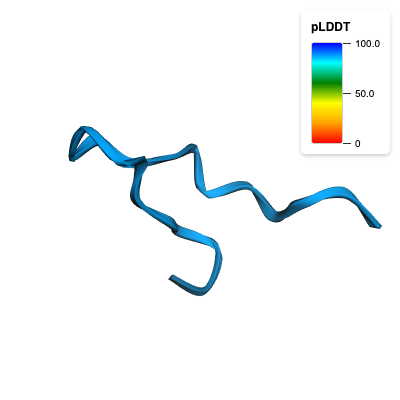

In [7]:
# Inspect the fold colored by pLDDT confidence.
trpcage_structure.visualize(style="cartoon", color_by="bfactor")

## Advanced usage: a two-chain complex and PAE

Human insulin provides a small protein complex with two chains. This second prediction uses one candidate, fewer denoising steps and recycling cycles, and requests the full PAE matrix. These reduced settings trade sampling and refinement for runtime; they are demonstration settings rather than accuracy recommendations.

PAE measures uncertainty in relative token placement, in angstroms. Its dimensions follow model tokens, which need not correspond one-to-one to residues for ligands or modified residues. Mol-1 also accepts ligand chains specified using the shared `Chain` SMILES or CCD-code fields.

In [8]:
# Preserve the A and B chain identifiers in the predicted complex.
insulin_complex = Complex(chains=[
    Chain(id="A", sequence="GIVEQCCTSICSLYQLENYCN", entity_type="protein"),
    Chain(id="B", sequence="FVNQHLCGSHLVEALYLVCGERGFFYTPKT", entity_type="protein"),
])
insulin_inputs = Mol1Input(complexes=[insulin_complex])
insulin_config = Mol1Config(
    device=device,
    use_msa=False,
    seed=101,
    num_samples=1,
    num_steps=100,
    num_cycles=10,
    include_pae_matrix=True,
)

insulin_result = run_mol1_prediction(insulin_inputs, insulin_config)

Connecting to modal container: 0it [00:00, ?it/s]

In [9]:
insulin_structure = insulin_result.structures[0]
insulin_metrics = insulin_structure.metrics
pae = insulin_metrics["pae"]

display({
    "input_chains": len(insulin_complex.chains),
    "avg_plddt (0–100)": insulin_metrics["avg_plddt"],
    "chain_plddt (0–1)": insulin_metrics["chain_plddt"],
    "iptm (0–1)": insulin_metrics["iptm"],
    "avg_pae (angstroms)": insulin_metrics["avg_pae"],
    "pae_shape": (len(pae), len(pae[0])),
})

{'input_chains': 2,
 'avg_plddt (0–100)': 87.69908905029297,
 'chain_plddt (0–1)': [0.8752403855323792, 0.8781697154045105],
 'iptm (0–1)': 0.5396367907524109,
 'avg_pae (angstroms)': 6.511207234442394,
 'pae_shape': (51, 51)}

## Export results

Export the structures as mmCIF using `file_format="cif"`. Each named export directory contains `structure_0.cif`; the structure B-factor values carry pLDDT confidence.

In [10]:
output_dir = Path("example_output")

result.export(name="trpcage", export_path=output_dir, file_format="cif")
insulin_result.export(name="insulin", export_path=output_dir, file_format="cif")

display(sorted(output_dir.glob("*/structure_*.cif")))

[PosixPath('example_output/insulin/structure_0.cif'),
 PosixPath('example_output/trpcage/structure_0.cif')]